# Xử lý dữ liệu (Data Processing) – Nhận diện ngôn ngữ ký hiệu từ video

**BTL Khai phá dữ liệu – HK261.**

Notebook này làm sạch tập `train` dựa trên kết quả EDA (thư mục `eda/`) và tạo ra một **manifest** dùng chung cho mọi mô hình (SVM, CNN-LSTM, ViT) và app demo. Các phép biến đổi áp dụng cho từng video lúc train/test (lọc khung đơn sắc, lấy 16 khung, tăng cường, chuẩn hoá) nằm trong module `preprocess.py` cạnh notebook này.

| Bước | Việc | Kỹ thuật tiền xử lý dữ liệu |
|---|---|---|
| 1 | Kiểm tra toàn vẹn: đọc được, có khung | Xử lý dữ liệu thiếu |
| 2 | Khử trùng lặp theo MD5 | Dư thừa dữ liệu (redundancy) |
| 3 | Loại video xung đột nhãn | Dữ liệu không nhất quán |
| 4 | Loại video rỗng (không còn khung hợp lệ) | Xử lý dữ liệu thiếu |
| 5 | Đánh dấu khung đơn sắc (khung nhiễu) | Nhiễu (noisy data) |
| 6 | Lấy đều T = 16 khung trên các khung hợp lệ | Lấy mẫu / rời rạc hoá theo thời gian |
| 7 | Chuẩn hoá z-score theo ImageNet | Chuẩn hoá (normalization) |
| 8 | Chia 5 fold phân tầng theo lớp, không để bản sao nằm ở cả hai phía | Đánh giá mô hình |
| 9 | Trọng số lớp cho dữ liệu mất cân bằng | Mất cân bằng lớp |
| 10 | Tăng cường dữ liệu (chỉ train) | Thu thập thêm dữ liệu nhân tạo |

**Đầu vào:** `../data/dataset/` (chỉ đọc), `../eda/02_data_quality/video_quality_flags.csv` (để đối chiếu).
**Đầu ra** (`output/`): `manifest_clean.csv`, `removed.csv`, `test_manifest.csv`, `class_weights.csv`, `processing_summary.csv`, `class_counts_before_after.csv`, hình trong `output/figures/`.

In [1]:
import os, sys, json, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

PROC = Path.cwd()                     
ROOT = PROC.parent                    
DATASET = next((p for p in [ROOT / 'data' / 'dataset', ROOT / 'dataset'] if p.exists()), ROOT / 'data' / 'dataset')
TRAIN = DATASET / 'train'
EDA = ROOT / 'eda'
OUT = PROC / 'output'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROC))
import preprocess as pp

SEED = 42
N_FOLDS = 5          # chia 5 phần -> mỗi phần ~20%
VAL_FOLD = 0         # phần dùng làm validation chung cho mọi mô hình
N_WORKERS = max(1, (os.cpu_count() or 2))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

print('Dataset:', DATASET, '| tồn tại:', DATASET.exists())
print('Số luồng xử lý song song:', N_WORKERS)

Dataset: /sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Downloads/data_mining-sign-language/data/dataset | tồn tại: True
Số luồng xử lý song song: 4


## 0. Nạp danh sách video và nhãn

Tên lớp trong `label_mapping.pkl` ở dạng Unicode **NFD** (dấu tách khỏi chữ), còn tên thư mục có thể là NFC hoặc NFD tuỳ hệ điều hành và cách giải nén. Hai chuỗi trông giống hệt nhau nhưng so sánh trực tiếp sẽ khác nhau, nên mọi tên lớp đều được chuẩn hoá về NFC bằng `pp.nfc()` trước khi tra nhãn.

In [2]:
label_map = pp.load_label_mapping(DATASET / 'label_mapping.pkl')     # {tên lớp NFC: 0..99}
dirs = pp.class_dirs(TRAIN)                                            # {tên lớp NFC: tên thư mục thật}

assert set(dirs) == set(label_map), 'Tên thư mục lớp không khớp label_mapping sau khi chuẩn hoá NFC'
assert sorted(label_map.values()) == list(range(100))

rows = []
for cls, d in sorted(dirs.items()):
    for f in pp.list_videos(TRAIN / d):
        rows.append({'cls': cls, 'label_idx': label_map[cls], 'file': f, 'path': str(TRAIN / d / f)})
raw = pd.DataFrame(rows)
print(f'{len(raw)} video train, {raw.cls.nunique()} lớp')
raw.head()

3875 video train, 100 lớp


,cls,label_idx,file,path
0,An ủi,0,126225.mp4,/sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Dow...
1,An ủi,0,127824.mp4,/sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Dow...
2,An ủi,0,127824_1.mp4,/sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Dow...
3,An ủi,0,127824_2.mp4,/sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Dow...
4,An ủi,0,127824_3.mp4,/sessions/rcw-01v8cmxqiz3hfrgbv82mogkd/mnt/Dow...


## Bước 1. Kiểm tra toàn vẹn và quét từng video

Mỗi video được đọc **một lần** (`pp.scan_video`) để lấy cùng lúc:
- `md5`: mã băm nội dung tệp, hai tệp cùng md5 là giống nhau từng byte;
- `n_frames`: số khung giải mã được;
- `valid_idx`: chỉ số các khung **không** đơn sắc (độ lệch chuẩn điểm ảnh lớn nhất giữa 3 kênh ≥ 3, cùng ngưỡng với EDA).

Quét song song bằng nhiều tiến trình để tiết kiệm thời gian.

In [3]:
t0 = time.time()
with ProcessPoolExecutor(N_WORKERS) as ex:
    scans = list(ex.map(pp.scan_video, raw.path, chunksize=8))
scan = pd.DataFrame(scans).drop(columns=['path'])
raw = pd.concat([raw.reset_index(drop=True), scan], axis=1)
print(f'Quét {len(raw)} video trong {time.time() - t0:.0f}s')

unreadable = raw[~raw.readable]
print('Không đọc được:', len(unreadable))
print('Có 0 khung:', int((raw.n_frames == 0).sum()))
print('Phân bố số khung:', raw.n_frames.value_counts().sort_index().to_dict())

Quét 3875 video trong 38s
Không đọc được: 0
Có 0 khung: 0
Phân bố số khung: {16: 26, 17: 4, 18: 1, 21: 1, 23: 4, 25: 2, 29: 5, 30: 3832}


**Đối chiếu với EDA.** Số khung đơn sắc mỗi video (`n_frames − n_valid`) phải khớp với cột `solid_frames` trong `video_quality_flags.csv` của nhóm EDA. Nếu khớp hoàn toàn thì bước quét ở đây đáng tin.

In [4]:
flags_path = EDA / '02_data_quality' / 'video_quality_flags.csv'
if flags_path.exists():
    flags = pd.read_csv(flags_path, encoding='utf-8-sig')
    flags = flags[flags.split == 'train'].assign(cls=lambda d: d.cls.map(pp.nfc))
    chk = raw.merge(flags[['cls', 'file', 'solid_frames']], on=['cls', 'file'], how='left')
    chk['solid_here'] = chk.n_frames - chk.n_valid
    print('Video khớp được với bảng EDA:', int(chk.solid_frames.notna().sum()), '/', len(chk))
    print('Video có số khung đơn sắc KHÁC EDA:', int((chk.solid_here != chk.solid_frames).sum()))
else:
    print('Không tìm thấy', flags_path, '- bỏ qua bước đối chiếu')

Video khớp được với bảng EDA: 3875 / 3875
Video có số khung đơn sắc KHÁC EDA: 0


## Bước 2. Khử trùng lặp theo MD5

EDA cho thấy 1,069 tệp có hậu tố `_1`, `_2`, `_3` là bản sao y hệt bản gốc. Nếu giữ lại, bản gốc có thể nằm ở train còn bản sao nằm ở validation → mô hình "đã thấy đề" và điểm validation bị thổi phồng (rò rỉ dữ liệu).

Cách làm: gom nhóm theo `md5`, mỗi nhóm giữ **một** tệp, ưu tiên tệp không có hậu tố `_N`, sau đó theo tên tệp.

In [5]:
raw['is_copy_name'] = raw.file.str.contains(r'_\d+\.\w+$', regex=True)
raw = raw.sort_values(['md5', 'is_copy_name', 'cls', 'file']).reset_index(drop=True)

removed = [] 

n_cls_per_md5 = raw.groupby('md5').cls.nunique()
conflict_md5 = set(n_cls_per_md5[n_cls_per_md5 > 1].index)

first = raw.groupby('md5').head(1)
dup = raw.drop(first.index)
keep_name = first.set_index('md5').apply(lambda r: f"{r.cls}/{r.file}", axis=1)
for r in dup[~dup.md5.isin(conflict_md5)].itertuples():
    removed.append({'cls': r.cls, 'file': r.file, 'md5': r.md5, 'step': 2,
                    'reason': 'bản sao (trùng MD5)', 'kept_as': keep_name[r.md5]})
step2 = first.copy()

print(f'{len(raw)} tệp -> {len(step2)} video duy nhất (loại {len(dup)} bản sao)')
print('Trong đó tệp có hậu tố _N:', int(raw.is_copy_name.sum()))

3875 tệp -> 2776 video duy nhất (loại 1099 bản sao)
Trong đó tệp có hậu tố _N: 1069


## Bước 3. Loại video xung đột nhãn

Một nội dung (cùng md5) nằm ở **hai lớp khác nhau** thì chắc chắn có một nhãn sai. Nhóm không có người am hiểu ngôn ngữ ký hiệu để xác minh nhãn đúng, nên mặc định loại **toàn bộ** các nhóm này (có thể đổi bằng cách sửa danh sách `KEEP_LABEL` bên dưới sau khi xem video).

In [6]:
conflict = raw[raw.md5.isin(conflict_md5)].sort_values(['md5', 'cls', 'file'])
display(conflict[['md5', 'cls', 'file']])

KEEP_LABEL = {}

step3 = step2.copy()
for m in sorted(conflict_md5):
    grp = conflict[conflict.md5 == m]
    if m in KEEP_LABEL:
        step3.loc[step3.md5 == m, ['cls', 'label_idx']] = [KEEP_LABEL[m], label_map[KEEP_LABEL[m]]]
        continue
    for r in grp.itertuples():          
        removed.append({'cls': r.cls, 'file': r.file, 'md5': m, 'step': 3,
                        'reason': 'xung đột nhãn: cùng nội dung ở ' + ' / '.join(sorted(grp.cls.unique())),
                        'kept_as': ''})
    step3 = step3[step3.md5 != m]
print(f'{len(conflict_md5)} nội dung xung đột ({len(conflict)} tệp) -> còn {len(step3)} video')

,md5,cls,file
1645,6ed595951efe6e5ad6bab1162845cfe8,Chào,792094.mp4
1646,6ed595951efe6e5ad6bab1162845cfe8,Chậm lại,254739.mp4
3710,f766c09351f227464b885209391a7be9,Chào,392683.mp4
3711,f766c09351f227464b885209391a7be9,Chào,468203.mp4
3712,f766c09351f227464b885209391a7be9,Chậm lại,284430.mp4


2 nội dung xung đột (5 tệp) -> còn 2774 video


## Bước 4–5. Khung đơn sắc và video rỗng

**Khung đơn sắc** là khung gần như toàn một màu thuần (đỏ, xanh, tím…) chen vào video, giống tấm bìa màu dán vào giữa cuốn flipbook. EDA cho thấy chúng chỉ có ở train, không có ở test, nên cần bỏ đi trước khi lấy 16 khung; nếu không, mô hình vừa mất thông tin ký hiệu vừa học tín hiệu không tồn tại ở dữ liệu thật.

- Khung đơn sắc **không bị xoá khỏi đĩa**; chỉ số các khung hợp lệ được lưu trong cột `valid_idx` của manifest và `pp.load_clip` chỉ lấy mẫu trong các khung đó.
- Video **không còn khung hợp lệ nào** (toàn bộ đơn sắc) bị loại khỏi tập train (bước 4).

In [7]:
empty = step3[step3.n_valid == 0]
for r in empty.itertuples():
    removed.append({'cls': r.cls, 'file': r.file, 'md5': r.md5, 'step': 4,
                    'reason': f'video rỗng: {r.n_frames}/{r.n_frames} khung đơn sắc', 'kept_as': ''})
clean = step3[step3.n_valid > 0].copy()
clean['n_solid'] = clean.n_frames - clean.n_valid

print('Video rỗng bị loại:', empty[['cls', 'file', 'n_frames']].to_dict('records'))
print(f'Còn {len(clean)} video, {clean.cls.nunique()} lớp')
aff = clean[clean.n_solid > 0]
print(f'Video có khung đơn sắc: {len(aff)} ({len(aff) / len(clean):.1%}), '
      f'trung bình {aff.n_solid.mean():.1f} khung/video')
print('Số khung hợp lệ: min', clean.n_valid.min(), '| trung vị', int(clean.n_valid.median()),
      '| video có < 16 khung hợp lệ:', int((clean.n_valid < pp.TARGET_FRAMES).sum()))

Video rỗng bị loại: [{'cls': 'Biết', 'file': '214576.mp4', 'n_frames': 16}, {'cls': 'Khai báo', 'file': '885339.mp4', 'n_frames': 23}]
Còn 2772 video, 100 lớp
Video có khung đơn sắc: 563 (20.3%), trung bình 12.2 khung/video
Số khung hợp lệ: min 9 | trung vị 30 | video có < 16 khung hợp lệ: 222


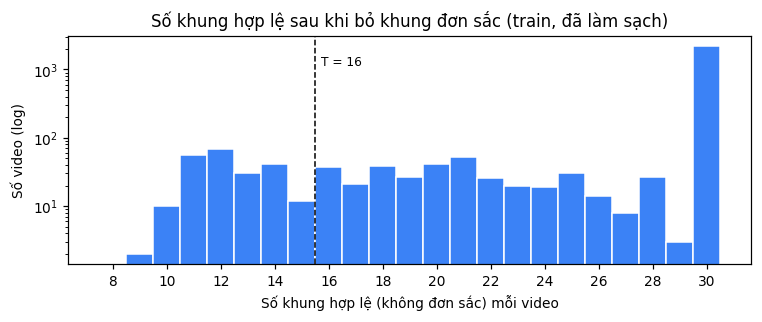

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clean.n_valid, bins=np.arange(7.5, 31.5), color='#3b82f6', edgecolor='white')
ax.axvline(pp.TARGET_FRAMES - 0.5, ls='--', c='k', lw=1)
ax.text(pp.TARGET_FRAMES - 0.3, ax.get_ylim()[1] * 0.5, 'T = 16', fontsize=8)
ax.set_yscale('log'); ax.set_xticks(range(8, 31, 2)); ax.set_xlabel('Số khung hợp lệ (không đơn sắc) mỗi video'); ax.set_ylabel('Số video (log)')
ax.set_title('Số khung hợp lệ sau khi bỏ khung đơn sắc (train, đã làm sạch)')
fig.tight_layout(); fig.savefig(FIG / 'valid_frames_hist.png', bbox_inches='tight'); plt.show()

## Bước 6. Lấy đều 16 khung: không lọc và có lọc khung đơn sắc

- **Không lọc** (cách lấy mẫu thông thường): `linspace` trên toàn bộ ~30 khung, kể cả khung đơn sắc.
- **Có lọc** (`pp.sample_indices`, dùng trong project): `linspace` trên **danh sách khung hợp lệ**. Video có ít hơn 16 khung hợp lệ thì `linspace` lặp đều các khung thay vì chỉ lặp khung cuối.

So sánh hai cách cho thấy bước 5 cần thiết thế nào. Hình dưới minh hoạ trên video bị ảnh hưởng nặng nhất còn giữ lại.

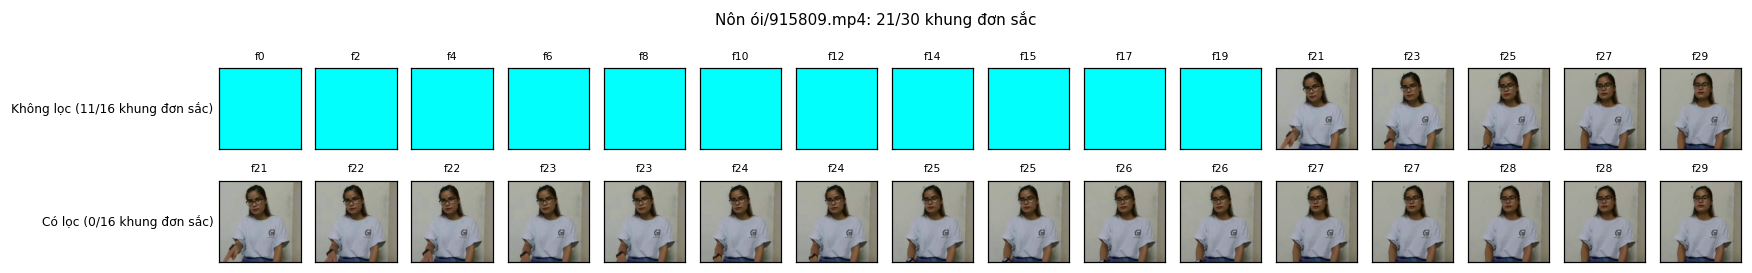

In [9]:
def naive_sampling(n, T=pp.TARGET_FRAMES):
    return np.linspace(0, n - 1, T).round().astype(int).tolist()

ex_row = clean.sort_values(['n_solid', 'cls'], ascending=[False, True]).iloc[0]
frames = pp.read_video(ex_row.path)
naive_idx = naive_sampling(len(frames))
new_idx = pp.sample_indices(pp.parse_idx(ex_row.valid_idx))
n_naive_solid = sum(pp.is_solid(frames[i]) for i in naive_idx)

fig, axes = plt.subplots(2, 16, figsize=(16, 2.6))
for row, (idx, name) in enumerate([(naive_idx, f'Không lọc ({n_naive_solid}/16 khung đơn sắc)'),
                                   (new_idx, 'Có lọc (0/16 khung đơn sắc)')]):
    for j, i in enumerate(idx):
        axes[row, j].imshow(frames[i]); axes[row, j].set_xticks([]); axes[row, j].set_yticks([])
        axes[row, j].set_title(f'f{i}', fontsize=7)
    axes[row, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=8)
fig.suptitle(f'{ex_row.cls}/{ex_row.file}: {ex_row.n_solid}/{ex_row.n_frames} khung đơn sắc', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'sampling_naive_vs_filtered.png', bbox_inches='tight'); plt.show()

In [10]:
def solid_hits(r):
    valid = set(pp.parse_idx(r.valid_idx))
    return sum(i not in valid for i in naive_sampling(r.n_frames))

clean['naive_solid_hits'] = clean.apply(solid_hits, axis=1)
hit = clean[clean.naive_solid_hits > 0]
print(f'Không lọc: {len(hit)} video có khung đơn sắc trong 16 khung đầu vào, '
      f'trung bình {hit.naive_solid_hits.mean():.1f}/16; {int((clean.naive_solid_hits >= 8).sum())} video có >= 8/16')
print('Có lọc: 0 video (theo cấu tạo)')

Không lọc: 563 video có khung đơn sắc trong 16 khung đầu vào, trung bình 6.4/16; 222 video có >= 8/16
Có lọc: 0 video (theo cấu tạo)


## Bước 7 và 10. Chuẩn hoá và tăng cường dữ liệu

Hai bước này chạy **mỗi lần mô hình đọc một video** nên nằm trong `preprocess.py`, không lưu ra đĩa (lưu sẵn 16 khung cho 2,772 video tốn khoảng 6.7 GB).

- **Chuẩn hoá** (`pp.normalize`): chia 255 rồi z-score từng kênh màu theo mean/std của ImageNet, vì backbone được huấn luyện trước trên ImageNet:
  $x'_c = (x_c - \mu_c)/\sigma_c$, với $\mu = (0.485, 0.456, 0.406)$, $\sigma = (0.229, 0.224, 0.225)$.
- **Tăng cường** (`pp.VideoAugmentation`, chỉ dùng cho train): giữ ngẫu nhiên một đoạn liên tục 80–100% số khung hợp lệ (đổi điểm bắt đầu/kết thúc và tốc độ), cắt ngẫu nhiên 85–100% khung hình, đổi độ sáng/tương phản/bão hoà ±25%. **Không lật ngang** vì tay trái/phải có thể đổi nghĩa.

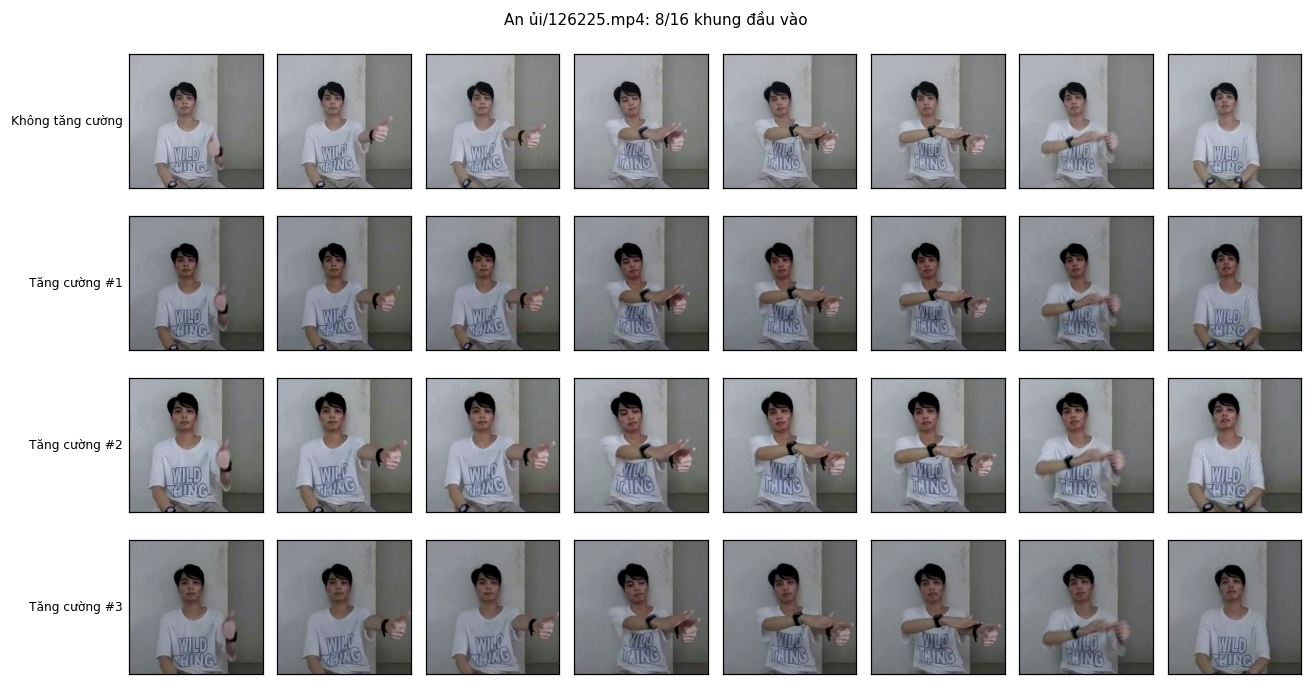

Đầu vào mô hình: (16, 3, 224, 224) float32 | mean 0.495 | std 0.642


In [11]:
aug = pp.VideoAugmentation()
rng = np.random.default_rng(SEED)
demo = clean.sort_values(['cls', 'file']).iloc[0]
versions = [('Không tăng cường', pp.load_clip(demo.path, demo.valid_idx))]
versions += [(f'Tăng cường #{k}', pp.load_clip(demo.path, demo.valid_idx, aug=aug, rng=rng)) for k in (1, 2, 3)]

fig, axes = plt.subplots(len(versions), 8, figsize=(12, 6.4))
for r, (name, clip) in enumerate(versions):
    for j, t in enumerate(range(0, 16, 2)):
        axes[r, j].imshow(clip[t]); axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
    axes[r, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=8)
fig.suptitle(f'{demo.cls}/{demo.file}: 8/16 khung đầu vào', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'augmentation_examples.png', bbox_inches='tight'); plt.show()

x = pp.normalize(versions[0][1])
print('Đầu vào mô hình:', x.shape, x.dtype, '| mean', round(float(x.mean()), 3), '| std', round(float(x.std()), 3))

## Bước 8. Chia train / validation

Chỉ tập `train` có nhãn nên validation phải tách từ chính nó. Dùng `StratifiedKFold` (5 phần, `shuffle=True`, `random_state=42`):
- **không rò rỉ**: sau bước 2 mỗi nội dung (md5) chỉ còn đúng 1 video, nên chia theo từng video cũng là chia theo nhóm nội dung; cell bên dưới kiểm tra lại điều này bằng `assert`. (Thử `StratifiedGroupKFold` với group = md5 thì có fold thiếu lớp, vì thuật toán đó chỉ cân bằng gần đúng.)
- **phân tầng theo nhãn**: mỗi phần giữ tỉ lệ các lớp gần giống toàn tập; lớp nhỏ nhất (5 video) có đúng 1 video mỗi phần, nên lớp nào cũng có mặt ở validation.

Phần `fold == 0` là validation chung cho **mọi** mô hình (SVM, CNN-LSTM, ViT) để so sánh công bằng; SVM chọn tham số bằng cross-validation trên 4 phần còn lại (fold 1–4).

In [ ]:
clean = clean.sort_values(['label_idx', 'file']).reset_index(drop=True)
clean['fold'] = -1
assert clean.md5.is_unique, 'Còn md5 trùng: phải khử trùng lặp trước khi chia'
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for k, (_, val_idx) in enumerate(skf.split(clean, clean.label_idx)):
    clean.loc[val_idx, 'fold'] = k

assert (clean.fold >= 0).all()
per_fold_classes = clean.groupby('fold').label_idx.nunique()
print('Số video mỗi fold:', clean.fold.value_counts().sort_index().to_dict())
print('Số lớp có mặt ở mỗi fold:', per_fold_classes.to_dict())
tr, va = clean[clean.fold != VAL_FOLD], clean[clean.fold == VAL_FOLD]
assert not set(tr.md5) & set(va.md5), 'Có md5 nằm ở cả train và validation!'
assert va.label_idx.nunique() == 100 and tr.label_idx.nunique() == 100
print(f'Train: {len(tr)} video | Validation (fold {VAL_FOLD}): {len(va)} video | không md5 nào nằm ở cả hai phía')

Số video mỗi fold: {0: 555, 1: 555, 2: 554, 3: 554, 4: 554}
Số lớp có mặt ở mỗi fold: {0: 100, 1: 100, 2: 100, 3: 100, 4: 100}
Train: 2217 video | Validation (fold 0): 555 video | không md5 nào nằm ở cả hai phía


## Bước 9. Mất cân bằng lớp và trọng số lớp

Sau khi làm sạch, lớp đông nhất có khoảng 10 lần số video của lớp ít nhất. Trọng số lớp kiểu *balanced* $w_c = N / (K \cdot n_c)$ (N: số video train, K = 100 lớp, $n_c$: số video lớp c) làm mỗi lớp đóng góp ngang nhau vào hàm mất mát:
- SVM: `class_weight='balanced'` (sklearn tự tính đúng công thức này);
- CNN-LSTM: `nn.CrossEntropyLoss(weight=torch.tensor(w))` với `w` đọc từ `class_weights.csv`.

In [13]:
w = pp.class_weights(tr.label_idx.values, 100)
inv = {v: k for k, v in label_map.items()}
cw = pd.DataFrame({'label_idx': range(100), 'cls': [inv[i] for i in range(100)],
                   'n_train': np.bincount(tr.label_idx, minlength=100), 'weight': w})
print('Số video train mỗi lớp: min', cw.n_train.min(), '| max', cw.n_train.max(),
      f'| chênh {cw.n_train.max() / cw.n_train.min():.1f} lần')
print('Trọng số: min', round(float(w.min()), 3), '| max', round(float(w.max()), 3))
cw.sort_values('n_train').head()

Số video train mỗi lớp: min 4 | max 41 | chênh 10.2 lần
Trọng số: min 0.541 | max 5.543


,label_idx,cls,n_train,weight
71,71,Sốt,4,5.5425
89,89,Xe máy,4,5.5425
77,77,Thương,4,5.5425
37,37,Ho,4,5.5425
86,86,Vâng lời,4,5.5425


## Tập test (public, private)

Tập test **không** bị làm sạch (file nộp phải có đủ 1,630 và 2,859 dòng); lúc dự đoán `pp.load_clip` tự tính khung hợp lệ cho từng video. Ở đây chỉ ghi lại danh sách tệp và md5, đánh dấu video trùng train (chỉ để diễn giải điểm, **không** dùng để tra nhãn), và chạy thử đường xử lý trên vài video test.

In [14]:
test_rows = []
train_md5 = set(raw.md5)
for split in ['public_test', 'private_test']:
    for f in pp.list_videos(DATASET / split):
        test_rows.append({'split': split, 'file': f})
test = pd.DataFrame(test_rows)
paths = [str(DATASET / r.split / r.file) for r in test.itertuples()]
with ProcessPoolExecutor(N_WORKERS) as ex:
    test['md5'] = list(ex.map(pp.md5_of, paths, chunksize=32))
test['dup_of_train'] = test.md5.isin(train_md5)
print(test.groupby('split').agg(n=('file', 'size'), dup_of_train=('dup_of_train', 'sum')))

sample = test.groupby('split').sample(4, random_state=SEED)
for r in sample.itertuples():
    clip = pp.load_clip(DATASET / r.split / r.file)
    assert clip.shape == (pp.TARGET_FRAMES, 224, 224, 3)
print('Chạy thử load_clip trên', len(sample), 'video test: OK')

                 n  dup_of_train
split                           
private_test  2859             0
public_test   1630           157


Chạy thử load_clip trên 8 video test: OK


## Lưu kết quả

In [15]:
manifest = clean.assign(rel_path=lambda d: 'train/' + d.cls + '/' + d.file)[
    ['cls', 'label_idx', 'file', 'rel_path', 'md5', 'n_frames', 'n_valid', 'n_solid', 'valid_idx', 'fold']]
manifest.to_csv(OUT / 'manifest_clean.csv', index=False, encoding='utf-8')

rm = pd.DataFrame(removed).sort_values(['step', 'cls', 'file'])
rm.to_csv(OUT / 'removed.csv', index=False, encoding='utf-8')
test.to_csv(OUT / 'test_manifest.csv', index=False, encoding='utf-8')
cw.to_csv(OUT / 'class_weights.csv', index=False, encoding='utf-8')

before = raw.groupby('cls').size().rename('n_before')
after = manifest.groupby('cls').size().rename('n_after')
counts = pd.concat([before, after], axis=1).fillna(0).astype(int)
counts['n_removed'] = counts.n_before - counts.n_after
counts = counts.sort_values('n_after', ascending=False)
counts.to_csv(OUT / 'class_counts_before_after.csv', encoding='utf-8')

summary = pd.DataFrame([
    ('Ban đầu', len(raw), '3,875 tệp train'),
    ('Bước 1 – toàn vẹn', int(raw.readable.sum()), 'tệp đọc được'),
    ('Bước 2 – khử trùng lặp MD5', len(step2), f'loại {len(raw) - len(step2)} bản sao'),
    ('Bước 3 – xung đột nhãn', len(step3), f'loại {len(step2) - len(step3)} video ({len(conflict_md5)} nội dung)'),
    ('Bước 4 – video rỗng', len(clean), f'loại {len(step3) - len(clean)} video'),
    ('Bước 5 – khung đơn sắc', len(clean), f'{int((clean.n_solid > 0).sum())} video có khung bị bỏ qua'),
    ('Bước 8 – train / validation', len(clean), f'{len(tr)} / {len(va)}'),
], columns=['Bước', 'Số video còn lại', 'Ghi chú'])
summary.to_csv(OUT / 'processing_summary.csv', index=False, encoding='utf-8')
json.dump({'seed': SEED, 'n_folds': N_FOLDS, 'val_fold': VAL_FOLD, 'target_frames': pp.TARGET_FRAMES,
           'solid_std': pp.SOLID_STD, 'n_raw': len(raw), 'n_clean': len(clean),
           'n_train': len(tr), 'n_val': len(va), 'n_removed': len(rm)},
          open(OUT / 'processing_config.json', 'w'), ensure_ascii=False, indent=2)
summary

,Bước,Số video còn lại,Ghi chú
0,Ban đầu,3875,"3,875 tệp train"
1,Bước 1 – toàn vẹn,3875,tệp đọc được
2,Bước 2 – khử trùng lặp MD5,2776,loại 1099 bản sao
3,Bước 3 – xung đột nhãn,2774,loại 2 video (2 nội dung)
4,Bước 4 – video rỗng,2772,loại 2 video
5,Bước 5 – khung đơn sắc,2772,563 video có khung bị bỏ qua
6,Bước 8 – train / validation,2772,2217 / 555


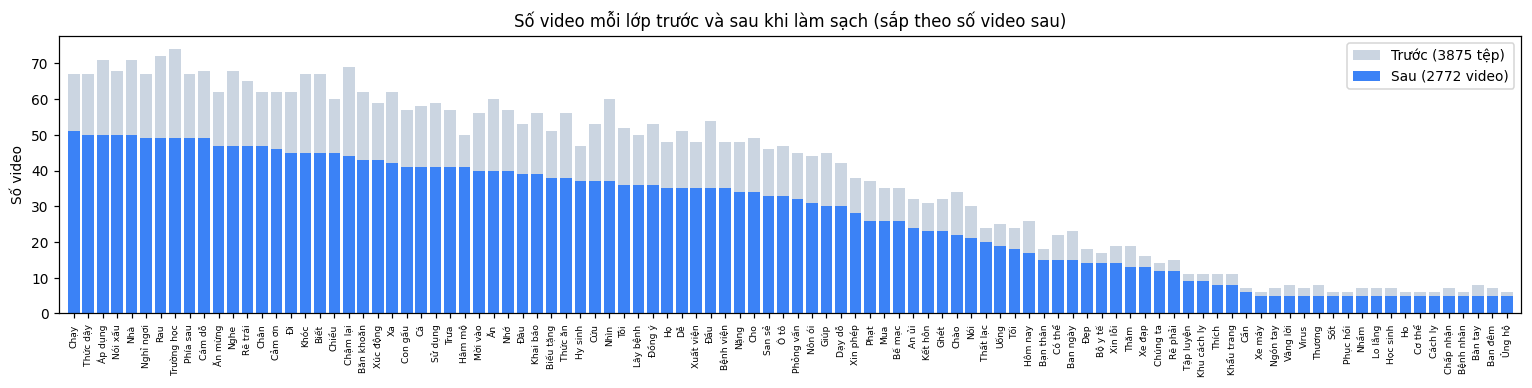

 step                                         reason  số video
    2                            bản sao (trùng MD5)      1096
    3 xung đột nhãn: cùng nội dung ở Chào / Chậm lại         5
    4                video rỗng: 16/16 khung đơn sắc         1
    4                video rỗng: 23/23 khung đơn sắc         1


In [16]:
fig, ax = plt.subplots(figsize=(14, 3.6))
x = np.arange(len(counts))
ax.bar(x, counts.n_before, color='#cbd5e1', label=f'Trước ({len(raw)} tệp)')
ax.bar(x, counts.n_after, color='#3b82f6', label=f'Sau ({len(manifest)} video)')
ax.set_xticks(x); ax.set_xticklabels(counts.index, rotation=90, fontsize=6)
ax.set_ylabel('Số video'); ax.legend(); ax.set_xlim(-1, len(x))
ax.set_title('Số video mỗi lớp trước và sau khi làm sạch (sắp theo số video sau)')
fig.tight_layout(); fig.savefig(FIG / 'class_counts_before_after.png', bbox_inches='tight'); plt.show()
print(rm.groupby(['step', 'reason']).size().rename('số video').reset_index().to_string(index=False))

## Đầu ra được dùng ở các phần sau

| Tệp | Nội dung | Dùng ở |
|---|---|---|
| `manifest_clean.csv` | 2,772 video train sạch: nhãn, chỉ số khung hợp lệ, fold (fold 0 là validation chung) | Trích đặc trưng, SVM, CNN-LSTM, ViT |
| `test_manifest.csv` | Danh sách video public / private test theo thứ tự cố định, kèm MD5 | Trích đặc trưng, ghi file nộp |
| `class_weights.csv` | Trọng số lớp tính trên phần train | Hàm mất mát của CNN-LSTM, ViT |
| `preprocess.py` | Lọc khung đơn sắc, lấy 16 khung, tăng cường, chuẩn hoá ImageNet | Mọi bước đọc video: trích đặc trưng, huấn luyện, dự đoán, demo |

Mọi mô hình đọc video qua cùng `preprocess.py` và dùng chung cách chia fold, nên kết quả trên fold 0 so sánh trực tiếp được với nhau.